# Notebook 02 – Làm sạch dữ liệu & Kỹ thuật tạo đặc trưng (Data Cleaning & Feature Engineering)

**Quy trình thực hiện tuần tự (bám sát Mục 3.3, 3.4 & 4.1 Báo cáo):**
1. **Làm sạch 6 bước chống rò rỉ dữ liệu (Cell 1 → 4):** (1) Chuẩn hóa `holiday` & trích `53` ngày lễ $\rightarrow$ (2) Khử trùng mốc giờ `date_time` $\rightarrow$ (3) Đổi Kelvin sang `°C` $\rightarrow$ (4) Lọc `11` dòng ngoại lai vật lý $\rightarrow$ (5) Dựng lưới giờ liên tục `52.551` giờ (`reindex`) $\rightarrow$ (6) Tính chuẩn xác 3 biến trễ `lag_1h, lag_24h, roll_3h` và lọc mẫu hợp lệ (`34.833` dòng).
2. **Tạo đặc trưng & Đóng gói (Cell 5 → 7):** Xây dựng **Bộ đặc trưng A** (`23` biến Lịch + Thời tiết) và **Bộ đặc trưng B** (`26` biến = Bộ A + 3 biến trễ), lưu ra `clean_data.parquet` + `clean_data.json` và kiểm chứng tương quan.

### Bước 1: Đọc dữ liệu thô, chuẩn hóa cột `holiday` & Lưu danh sách 53 ngày lễ
* **Tại sao phải làm đầu tiên?** Nhãn tên lễ chỉ xuất hiện ở mốc `00:00:00`. Ta phải gom danh sách ngày lễ (`holiday_days`) ngay từ đầu để lát nữa gán cờ `is_holiday = 1` cho toàn bộ 24 giờ của ngày hôm đó (kể cả khi ngày lễ đó bị thiếu mốc `00:00` hoặc có dòng trùng giờ).

In [1]:
import json
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RAW_PATH = os.path.join("..", "data", "raw", "metro_interstate_traffic_volume.csv")
PROCESSED_DIR = os.path.join("..", "data", "processed")
FIGURES_DIR = os.path.join("..", "figures")
os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

TEST_START = pd.Timestamp("2018-01-01")

# Đọc dữ liệu gốc và khởi tạo nhật ký theo dõi số dòng qua từng bước (preprocessing_log)
df = pd.read_csv(RAW_PATH)
df["date_time"] = pd.to_datetime(df["date_time"])
preprocessing_log = [{"moc_xu_ly": "1. Dữ liệu gốc (raw)", "mo_ta": "File CSV từ UCI ID 492", "so_dong": len(df)}]

# Bước 1: Chữ 'None' ngày thường bị pandas đọc nhầm thành NaN -> trả lại thành chuỗi 'None'
df["holiday"] = df["holiday"].fillna("None").astype(str).str.strip()

# Lấy danh sách các NGÀY lễ duy nhất (chuẩn hóa về 00:00 bằng .dt.normalize())
holiday_rows = df[df["holiday"] != "None"]
holiday_days = set(holiday_rows["date_time"].dt.normalize())

print(f"Số dòng ban đầu: {len(df):,} | Số dòng gắn nhãn lễ lúc 0h: {len(holiday_rows)} -> Gom được: {len(holiday_days)} ngày lễ duy nhất")

Số dòng ban đầu: 48,204 | Số dòng gắn nhãn lễ lúc 0h: 61 -> Gom được: 53 ngày lễ duy nhất


### Bước 2: Sắp xếp thời gian ổn định & Khử trùng lặp theo mốc giờ `date_time`
* **Tại sao gộp theo `date_time`?** Trong 1 giờ có thể xuất hiện nhiều bản tin thời tiết nhưng `traffic_volume` hoàn toàn giống nhau. Chuỗi thời gian theo giờ bắt buộc mỗi mốc giờ chỉ có **duy nhất 1 dòng** để không làm sai lệch phép dịch giờ `shift()` và không nhân bản mẫu học.

In [2]:
so_trung_hoan_toan = int(df.duplicated().sum())
so_trung_date_time = int(df.duplicated(subset=["date_time"]).sum())

# Dùng mergesort để giữ nguyên thứ tự gốc của các dòng cùng giờ, sau đó giữ lại dòng đầu tiên
df = df.sort_values("date_time", kind="mergesort")
df = df.drop_duplicates(subset=["date_time"], keep="first").reset_index(drop=True)
assert df["date_time"].is_unique

preprocessing_log.append({
    "moc_xu_ly": "2. Sau loại trùng date_time",
    "mo_ta": f"Loại {so_trung_date_time} dòng trùng giờ (gồm {so_trung_hoan_toan} dòng trùng cả 9 cột)",
    "so_dong": len(df),
})
print(f"Đã loại {so_trung_date_time:,} dòng trùng giờ -> Còn lại: {len(df):,} mốc giờ duy nhất")

Đã loại 7,629 dòng trùng giờ -> Còn lại: 40,575 mốc giờ duy nhất


### Bước 3 & Bước 4: Đổi nhiệt độ từ Kelvin sang độ C & Loại bỏ 11 dòng ngoại lai vật lý
* **Nguyên tắc:** Chỉ lọc bỏ các điểm **sai lệch vật lý do hỏng cảm biến** (`temp_c <= -50°C` ứng với `0 K`, và `rain_1h >= 500 mm/giờ`). Tuyệt đối **không dùng IQR cắt ngọn `traffic_volume`** vì các giờ cao điểm > 6.000 xe là hành vi giao thông thật cần dự báo.

In [3]:
# Bước 3: Chuyển nhiệt độ từ Kelvin (K) sang độ Celsius (°C) cho trực quan
df["temp_c"] = df["temp"] - 273.15
cot_so = ["temp_c", "rain_1h", "snow_1h", "clouds_all", "traffic_volume"]
desc_truoc = df[cot_so].describe().T[["mean", "std", "min", "max"]]

# Bước 4: Lọc bỏ ngoại lai vật lý lỗi thiết bị đo
mask_temp = df["temp_c"] <= -50
mask_rain = df["rain_1h"] >= 500
df = df[~(mask_temp | mask_rain)].reset_index(drop=True)
desc_sau = df[cot_so].describe().T[["mean", "std", "min", "max"]]

preprocessing_log.append({
    "moc_xu_ly": "3. Sau lọc ngoại lai vật lý",
    "mo_ta": f"Loại {int(mask_temp.sum())} dòng lỗi nhiệt độ và {int(mask_rain.sum())} dòng lỗi mưa",
    "so_dong": len(df),
})

print(f"Đã loại {int(mask_temp.sum())} dòng temp_c <= -50°C và {int(mask_rain.sum())} dòng rain_1h >= 500mm -> Còn: {len(df):,} dòng")
print("Bảng đối chiếu thống kê TRƯỚC và SAU khi lọc ngoại lai vật lý (Bảng 4.1 Báo cáo):")
display(pd.concat({"TRƯỚC LỌC": desc_truoc, "SAU LỌC": desc_sau}, axis=1).round(2))

Đã loại 10 dòng temp_c <= -50°C và 1 dòng rain_1h >= 500mm -> Còn: 40,564 dòng
Bảng đối chiếu thống kê TRƯỚC và SAU khi lọc ngoại lai vật lý (Bảng 4.1 Báo cáo):


TRƯỚC LỌC                            SAU LỌC                         
                    mean      std     min      max     mean      std    min      max
temp_c              8.17    13.82 -273.15    36.92     8.24    13.09 -29.76    36.92
rain_1h             0.32    48.81    0.00  9831.30     0.08     0.77   0.00    55.63
snow_1h             0.00     0.01    0.00     0.51     0.00     0.01   0.00     0.51
clouds_all         44.20    38.68    0.00   100.00    44.21    38.68   0.00   100.00
traffic_volume   3290.65  1984.77    0.00  7280.00  3291.08  1984.64   0.00  7280.00

### Bước 5 & Bước 6: Dựng lưới giờ liên tục (`reindex`) & Tính 3 đặc trưng trễ không rò rỉ dữ liệu
* **Tại sao phải `reindex` lên lưới `52.551` giờ trước khi tính `lag`?** Vì dữ liệu bị khuyết đứt quãng `11.987` giờ. Trải lên lưới giờ liên tục biến các giờ mất tín hiệu thành `NaN`, đảm bảo:
  * `lag_1h = shift(1)`: Đúng lưu lượng của **1 giờ đồng hồ liền trước** ($y_{t-1}$).
  * `lag_24h = shift(24)`: Đúng lưu lượng **cùng giờ ngày hôm trước** ($y_{t-24}$).
  * `roll_3h = shift(1).rolling(3).mean()`: Trung bình cộng của **3 giờ liền trước** $(y_{t-3} + y_{t-2} + y_{t-1}) / 3$ — đặt `.shift(1)` đứng trước `.rolling(3)` để không bao giờ nhìn trộm đáp án $y_t$!

In [4]:
# Bước 5: Khởi tạo khung lịch chuẩn cách đều từng 1 giờ từ đầu đến cuối giai đoạn đo
full_range = pd.date_range(start=df["date_time"].min(), end=df["date_time"].max(), freq="h")
missing_hours = full_range.difference(df["date_time"])

df_grid = df.set_index("date_time").reindex(full_range)
df_grid.index.name = "date_time"
preprocessing_log.append({
    "moc_xu_ly": "4. Lưới giờ liên tục (reindex)",
    "mo_ta": f"Trải lên lưới 1h; phát hiện {len(missing_hours)} giờ khuyết (NaN)",
    "so_dong": len(df_grid),
})

# Bước 6: Tính 3 đặc trưng trễ & trung bình trượt trực tiếp trên lưới giờ liên tục
df_grid["lag_1h"] = df_grid["traffic_volume"].shift(1)
df_grid["lag_24h"] = df_grid["traffic_volume"].shift(24)
df_grid["roll_3h"] = df_grid["traffic_volume"].shift(1).rolling(3).mean()

print("Minh họa cách 3 cột trễ sinh ra từ cột traffic_volume trên lưới giờ liên tục:")
display(df_grid[["traffic_volume", "lag_1h", "lag_24h", "roll_3h"]].iloc[24:30].round(1))

# Chỉ giữ lại các mốc giờ có số đo thực tế và có đủ cả 3 đặc trưng trễ (không bịa số nội suy)
df_clean = df_grid[df_grid["traffic_volume"].notna()].reset_index()
df_clean = df_clean.dropna(subset=["lag_1h", "lag_24h", "roll_3h"]).reset_index(drop=True)
df_clean["traffic_volume"] = df_clean["traffic_volume"].astype(int)
df_clean["clouds_all"] = df_clean["clouds_all"].astype(int)

preprocessing_log.append({
    "moc_xu_ly": "5. Tập sạch cuối cùng (đủ lag)",
    "mo_ta": "Giữ giờ có quan sát thực tế và đủ lag_1h, lag_24h, roll_3h",
    "so_dong": len(df_clean),
})
print(f"Số giờ khuyết phát hiện: {len(missing_hours):,} giờ ({len(missing_hours)/len(full_range)*100:.2f}%) -> Tập sạch hoàn chỉnh: {len(df_clean):,} dòng")

Minh họa cách 3 cột trễ sinh ra từ cột traffic_volume trên lưới giờ liên tục:
Số giờ khuyết phát hiện: 11,987 giờ (22.81%) -> Tập sạch hoàn chỉnh: 34,833 dòng


,traffic_volume,lag_1h,lag_24h,roll_3h
date_time,,,,
2012-10-03 09:00:00,5471.0,6511.0,5545.0,NaN
2012-10-03 10:00:00,NaN,5471.0,4516.0,NaN
2012-10-03 11:00:00,NaN,NaN,4767.0,NaN
2012-10-03 12:00:00,5097.0,NaN,5026.0,NaN
2012-10-03 13:00:00,4887.0,5097.0,4918.0,NaN
2012-10-03 14:00:00,5337.0,4887.0,5181.0,NaN


### Tạo 3 nhóm đặc trưng & Thiết lập Bộ đặc trưng A (23 biến) và Bộ đặc trưng B (26 biến)
* **Loại bỏ có chủ đích:** Bỏ cột `year` (vì năm Test `2018` chưa từng xuất hiện ở Train `2012–2017`, mô hình cây không ngoại suy được theo năm) và bỏ `weather_description` (trùng lặp chi tiết với `weather_main`, gây đa cộng tuyến).
* **3 nhóm đặc trưng số hóa (26 biến):**
  1. **Lịch & Chu kỳ (`8` biến):** `hour`, `day_of_week`, `month`, `is_weekend`, `is_holiday` (lan truyền đủ 24h), `is_rush_hour` (7–9h hoặc 16–18h ngày làm việc), và cặp lượng giác `hour_sin`, `hour_cos` nối liền `23h` đêm với `0h` sáng.
  2. **Thời tiết (`15` biến):** `temp_c`, `rain_1h`, `snow_1h`, `clouds_all` + `11` cột One-Hot `wm_*` từ `weather_main`.
  3. **Trễ & Trung bình trượt (`3` biến):** `lag_1h`, `lag_24h`, `roll_3h`.

In [5]:
# 1. Nhóm đặc trưng Lịch & Chu kỳ (8 biến)
df_clean["hour"] = df_clean["date_time"].dt.hour
df_clean["day_of_week"] = df_clean["date_time"].dt.dayofweek
df_clean["month"] = df_clean["date_time"].dt.month
df_clean["is_weekend"] = (df_clean["day_of_week"] >= 5).astype(int)
df_clean["is_holiday"] = df_clean["date_time"].dt.normalize().isin(holiday_days).astype(int)

gio_cao_diem = df_clean["hour"].between(7, 9) | df_clean["hour"].between(16, 18)
ngay_lam_viec = (df_clean["is_weekend"] == 0) & (df_clean["is_holiday"] == 0)
df_clean["is_rush_hour"] = (gio_cao_diem & ngay_lam_viec).astype(int)

df_clean["hour_sin"] = np.sin(2 * np.pi * df_clean["hour"] / 24)
df_clean["hour_cos"] = np.cos(2 * np.pi * df_clean["hour"] / 24)

# 2. Nhóm đặc trưng Thời tiết: 4 biến định lượng + 11 biến giả One-Hot từ weather_main (15 biến)
weather_dummies = pd.get_dummies(df_clean["weather_main"], prefix="wm", dtype=int)
df_clean = pd.concat([df_clean, weather_dummies], axis=1)
WEATHER_ONEHOT_COLS = sorted(weather_dummies.columns.tolist())

# 3. Gom thành Bộ đặc trưng A (23 biến - dài hạn không biến trễ) và Bộ đặc trưng B (26 biến - ngắn hạn có lag)
CALENDAR_FEATURES = ["hour", "day_of_week", "month", "is_weekend", "is_rush_hour", "is_holiday", "hour_sin", "hour_cos"]
WEATHER_FEATURES = ["temp_c", "rain_1h", "snow_1h", "clouds_all"] + WEATHER_ONEHOT_COLS
LAG_FEATURES = ["lag_1h", "lag_24h", "roll_3h"]

FEATURES_A = CALENDAR_FEATURES + WEATHER_FEATURES
FEATURES_B = FEATURES_A + LAG_FEATURES

print(f"Bộ đặc trưng A: {len(FEATURES_A)} biến (8 Lịch + 15 Thời tiết) | Bộ đặc trưng B: {len(FEATURES_B)} biến (Bộ A + 3 Lag)")
display(df_clean[["date_time", "traffic_volume"] + CALENDAR_FEATURES + LAG_FEATURES].head(5).round(2))

Bộ đặc trưng A: 23 biến (8 Lịch + 15 Thời tiết) | Bộ đặc trưng B: 26 biến (Bộ A + 3 Lag)


,date_time,traffic_volume,hour,day_of_week,month,is_weekend,is_rush_hour,is_holiday,hour_sin,hour_cos,lag_1h,lag_24h,roll_3h
0,2012-10-03 15:00:00,5692,15,2,10,0,0,0,-0.71,-0.71,5337.0,5584.0,5107.00
1,2012-10-03 16:00:00,6137,16,2,10,0,1,0,-0.87,-0.50,5692.0,6015.0,5305.33
2,2012-10-03 21:00:00,2637,21,2,10,0,0,0,-0.71,0.71,2898.0,2361.0,3704.00
3,2012-10-03 22:00:00,1777,22,2,10,0,0,0,-0.50,0.87,2637.0,1529.0,3042.00
4,2012-10-03 23:00:00,1015,23,2,10,0,0,0,-0.26,0.97,1777.0,963.0,2437.33


### Lưu trữ dữ liệu sạch (`clean_data.parquet` & `clean_data.json`) và Tổng kết quy trình
* **Ý nghĩa 2 file đầu ra:**
  * `clean_data.parquet`: Lưu bảng sạch `34.833 dòng × 30 cột` dạng cột nén nhị phân, giữ nguyên kiểu `datetime64/int/float` và tối ưu tốc độ đọc và dung lượng lưu trữ cho bước mô hình hóa ở `note_03`.
  * `clean_data.json`: Lưu danh sách tên cột chuẩn của `FEATURES_A`, `FEATURES_B` và mốc chia tập `TEST_START = "2018-01-01"` để bước huấn luyện mô hình ở `note_03` đọc đồng bộ không lệch cột.

In [6]:
# 1. Xuất bảng dữ liệu sạch ra định dạng Parquet
df_out = df_clean[["date_time", "traffic_volume"] + FEATURES_B + ["weather_main", "holiday"]]
df_out.to_parquet(os.path.join(PROCESSED_DIR, "clean_data.parquet"), index=False)

# 2. Xuất từ điển cấu hình danh sách cột ra định dạng JSON
feature_sets = {
    "CALENDAR_FEATURES": CALENDAR_FEATURES,
    "WEATHER_FEATURES": WEATHER_FEATURES,
    "LAG_FEATURES": LAG_FEATURES,
    "FEATURES_A": FEATURES_A,
    "FEATURES_B": FEATURES_B,
    "TEST_START": "2018-01-01",
}
with open(os.path.join(PROCESSED_DIR, "clean_data.json"), "w", encoding="utf-8") as f:
    json.dump(feature_sets, f, indent=2)

# 3. Tổng kết số lượng bản ghi qua toàn bộ quy trình tiền xử lý (Hình 4.1 Báo cáo)
n_train = int((df_out["date_time"] < TEST_START).sum())
preprocessing_log += [
    {"moc_xu_ly": "Tập Train (< 2018-01-01)", "mo_ta": "Huấn luyện (81.4%)", "so_dong": n_train},
    {"moc_xu_ly": "Tập Test (>= 2018-01-01)", "mo_ta": "Kiểm tra (18.6%)", "so_dong": len(df_out) - n_train},
]

print(f"Đã xuất clean_data.parquet {df_out.shape} & clean_data.json thành công! Số ô trống còn sót: {int(df_out.isna().sum().sum())}")
display(pd.DataFrame(preprocessing_log))

Đã xuất clean_data.parquet (34833, 30) & clean_data.json thành công! Số ô trống còn sót: 0


,moc_xu_ly,mo_ta,so_dong
0,1. Dữ liệu gốc (raw),File CSV từ UCI ID 492,48204
1,2. Sau loại trùng date_time,Loại 7629 dòng trùng giờ (gồm 17 dòng trùng cả 9 cột),40575
2,3. Sau lọc ngoại lai vật lý,Loại 10 dòng lỗi nhiệt độ và 1 dòng lỗi mưa,40564
3,4. Lưới giờ liên tục (reindex),Trải lên lưới 1h; phát hiện 11987 giờ khuyết (NaN),52551
4,5. Tập sạch cuối cùng (đủ lag),"Giữ giờ có quan sát thực tế và đủ lag_1h, lag_24h, roll_3h",34833
5,Tập Train (< 2018-01-01),Huấn luyện (81.4%),28353
6,Tập Test (>= 2018-01-01),Kiểm tra (18.6%),6480


### Kiểm chứng mức độ tương quan của các đặc trưng mới với `traffic_volume`
* **Ý nghĩa:** Xác nhận hiệu quả của bước tạo đặc trưng trước khi đưa sang `note_03` (`lag_1h`, `roll_3h`, `lag_24h` tương quan dương rất mạnh `+0,83 → +0,92`; `hour_cos` đạt `-0,77` mạnh hơn gấp đôi cột `hour` gốc `+0,35`!).

Đã lưu ảnh tương quan: ..\figures\fig_feature_correlation.png


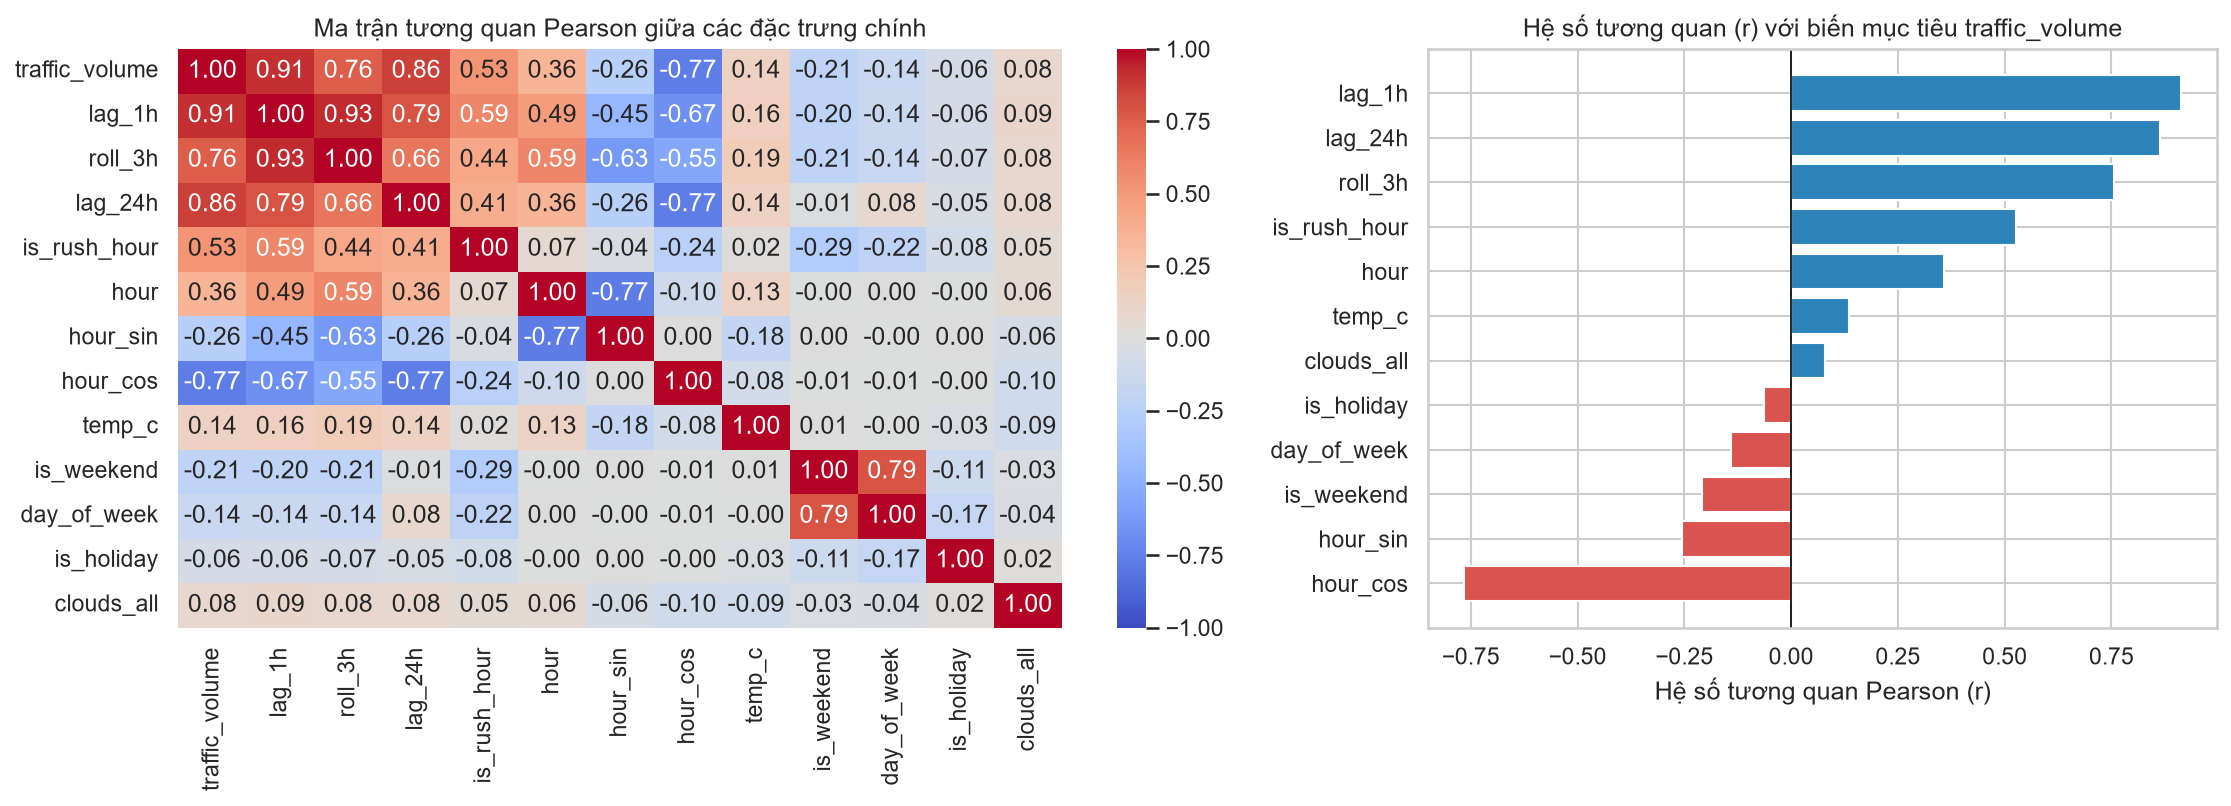

In [7]:
sns.set_theme(style="whitegrid", font_scale=1.0)
cot_tuong_quan = [
    "traffic_volume", "lag_1h", "roll_3h", "lag_24h",
    "is_rush_hour", "hour", "hour_sin", "hour_cos",
    "temp_c", "is_weekend", "day_of_week", "is_holiday", "clouds_all",
]
corr_matrix = df_out[cot_tuong_quan].corr()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.4, 1]})

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Ma trận tương quan Pearson giữa các đặc trưng chính")

corr_target = corr_matrix["traffic_volume"].drop("traffic_volume").sort_values()
mau_cot = ["#d9534f" if v < 0 else "#2b83ba" for v in corr_target.values]
axes[1].barh(corr_target.index, corr_target.values, color=mau_cot)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Hệ số tương quan (r) với biến mục tiêu traffic_volume")
axes[1].set_xlabel("Hệ số tương quan Pearson (r)")

plt.tight_layout()
duong_dan_anh = os.path.join(FIGURES_DIR, "fig_feature_correlation.png")
fig.savefig(duong_dan_anh, dpi=200, bbox_inches="tight")
print("Đã lưu ảnh tương quan:", duong_dan_anh)
plt.show()